# Прогнозирование FTSE: AR, RNN и LSTM

Решение по материалам семинара «MosPolytechSeminarNN» (Игнатенко М. В.).
Исследуются два предоставленных CSV: дневные цены и наблюдения с шагом 4 часа внутри торговой сессии.
Все расчёты используют только `Close`; `Volume` дневного файла не включается, чтобы набор признаков совпадал.
Две строки четырёхчасового файла без `Close` (24 и 31 декабря 2024, 12:00 UTC) исключены без интерполяции.
Пропуск `Volume` в последней дневной строке не влияет на расчёты. Исходные CSV сохранены без изменений.

**Задача:** сравнить авторегрессию и рекуррентные нейросети, изучить ошибки в начале апреля 2025 года,
объяснить слабые результаты нейросетей и проверить улучшения.

В Colab: **Среда выполнения → Выполнить всё**. Данные автоматически загружаются из этого репозитория,
если папки `data` рядом нет. Достаточно CPU. Обучение всех вариантов может занять несколько минут.


In [1]:
# В Colab основные пакеты уже установлены. Для локального запуска: pip install -r requirements.txt
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy==2.2.4', 'pandas': 'pandas==2.2.3',
            'matplotlib': 'matplotlib==3.10.1', 'sklearn': 'scikit-learn==1.6.1',
            'statsmodels': 'statsmodels==0.14.4', 'torch': 'torch==2.6.0'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])


## 1. Протокол эксперимента

Первые 60% наблюдений — обучение для подбора, следующие 20% — validation, последние 20% — test.
Порядок времени сохраняется. На validation выбираются лаг AR (1, 5, 10 или 30) и число эпох.
Затем модели заново обучаются на первых 80% с выбранными настройками. Тест не участвует в выборе.

Прогнозируем **одно следующее наблюдение**. После наступления следующего момента его фактическая цена
может использоваться для следующего прогноза. У четырёхчасового файла перерывы между сессиями длиннее 4 часов.
Это не прогноз всей тестовой траектории из одной начальной точки.

Даты сохраняются как в файлах, в UTC. Период падения задан как наблюдения с `2025-04-03 00:00 UTC`
до конца файла. Точное соответствие метки дате торговой сессии поставщик в CSV не описал;
мы не сдвигаем даты произвольно. Связь движения рынка с конкретным заявлением из условия
не проверяется по этим двум ценовым рядам.


## 2. Подготовка данных и метрики

In [2]:
"""Сравнение AR, RNN и LSTM: прогноз на одно следующее наблюдение."""
from pathlib import Path
import argparse
import json
import hashlib
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from statsmodels.tsa.ar_model import AutoReg

WINDOW = 30
MAX_EPOCHS = 150
PATIENCE = 20
SEEDS = (42, 7, 123)
DROP_START = pd.Timestamp('2025-04-03', tz='UTC')
DATASETS = {'daily': 'ftse_daily.csv', '4h': 'ftse_4h.csv'}


def load_data(path):
    data = pd.read_csv(path, thousands=',')
    data['Date'] = pd.to_datetime(data['Date'], utc=True, errors='raise')
    data['Close'] = pd.to_numeric(data['Close'], errors='raise')
    data = data.sort_values('Date').set_index('Date')
    if data.index.has_duplicates or data.index.isna().any():
        raise ValueError('Даты должны быть уникальными и заполненными')
    raw_rows = len(data)
    missing_dates = [str(date) for date in data.index[data.Close.isna()]]
    # Нет наблюдаемой цели: удаляем строку, не заполняя её будущими ценами.
    data = data.dropna(subset=['Close'])
    data.attrs.update(raw_rows=raw_rows, missing_close_dates=missing_dates)
    if not np.isfinite(data['Close']).all() or (data['Close'] <= 0).any():
        raise ValueError('Нужны конечные положительные цены')
    if len(data) < 120:
        raise ValueError('Недостаточно наблюдений для выбранного окна и разбиения')
    return data


def make_sequences(values, start, end, window=WINDOW):
    """Цель с индексом t использует только values[t-window:t]."""
    values = np.asarray(values, dtype=np.float32).reshape(-1)
    if not window <= start < end <= len(values):
        raise ValueError('Некорректные границы последовательностей')
    x = np.stack([values[t-window:t] for t in range(start, end)])[:, :, None]
    y = values[start:end, None]
    return torch.from_numpy(x), torch.from_numpy(y)


def metrics(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    if actual.shape != predicted.shape or actual.size == 0:
        raise ValueError('Метрики требуют непустых массивов одной формы')
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError('В метриках обнаружены NaN или inf')
    error = actual - predicted
    return {'MSE': float(np.mean(error**2)),
            'MAE': float(np.mean(np.abs(error))),
            'RMSE': float(np.sqrt(np.mean(error**2)))}

## 3. RNN и LSTM

Базовая RNN: 50 скрытых нейронов, 1 слой. Базовая LSTM: 50 нейронов, 2 слоя.
Варианты `_diff` учатся на $\Delta p_t=p_t-p_{t-1}$, используют 16 нейронов и 1 слой.
Прогноз цены восстанавливается как $\hat p_t=p_{t-1}+\widehat{\Delta p_t}$.
Для уровней используется MinMaxScaler, для разностей — StandardScaler. Каждый scaler обучается
только на доступной обучающей части. Дифференцирование само по себе не доказывает стационарность.

Общие настройки: окно 30, Adam с шагом 0.001, batch 16, ограничение нормы градиента 1,
не более 150 эпох, остановка после 20 эпох без улучшения validation.
Различия `_diff` включают и преобразование данных, и меньшую архитектуру; это не изолированная
оценка эффекта одного лишь дифференцирования. Все заранее заданные варианты сохраняются в сравнении.

In [3]:
class RecurrentModel(nn.Module):
    def __init__(self, kind, differenced=False):
        super().__init__()
        # Для разностей уменьшаем число параметров: выборка небольшая.
        hidden = 16 if differenced else 50
        layers = 1 if differenced or kind == 'RNN' else 2
        recurrent = nn.RNN if kind == 'RNN' else nn.LSTM
        self.recurrent = recurrent(1, hidden, num_layers=layers, batch_first=True)
        self.linear = nn.Linear(hidden, 1)

    def forward(self, x):
        # PyTorch по умолчанию создаёт нулевые h0 и c0 на нужном устройстве.
        output, _ = self.recurrent(x)
        return self.linear(output[:, -1, :])


def fit_network(kind, differenced, x, y, seed, epochs=MAX_EPOCHS, validation=None):
    torch.manual_seed(seed)
    model = RecurrentModel(kind, differenced)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(x, y), batch_size=16, shuffle=True,
        generator=torch.Generator().manual_seed(seed))
    criterion = nn.MSELoss()
    history, best_epoch, best_loss, stale = [], 1, np.inf, 0
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(batch_x)
        record = {'epoch': epoch, 'train_MSE_scaled': total / len(x)}
        if validation is not None:
            model.eval()
            with torch.no_grad():
                val_loss = criterion(model(validation[0]), validation[1]).item()
            record['validation_MSE_scaled'] = val_loss
            if val_loss < best_loss - 1e-7:
                best_epoch, best_loss, stale = epoch, val_loss, 0
            else:
                stale += 1
        history.append(record)
        if validation is not None and stale >= PATIENCE:
            break
    # При подборе возвращаем номер лучшей эпохи; финальная модель учится заново.
    return model, best_epoch, history


def neural_forecast(prices, fit_end, test_start, kind, differenced, seed):
    prices = np.asarray(prices, dtype=float)
    series = np.diff(prices) if differenced else prices
    offset = int(differenced)
    fit_boundary, test_boundary = fit_end-offset, test_start-offset
    scaler = StandardScaler() if differenced else MinMaxScaler()
    scaler.fit(series[:fit_boundary, None])
    scaled = scaler.transform(series[:, None]).ravel()
    x, y = make_sequences(scaled, WINDOW, fit_boundary)
    xv, yv = make_sequences(scaled, fit_boundary, test_boundary)
    _, best_epoch, history = fit_network(kind, differenced, x, y, seed,
                                        validation=(xv, yv))
    # После выбора эпох используем все первые 80% данных. Test остаётся закрытым.
    scaler.fit(series[:test_boundary, None])
    scaled = scaler.transform(series[:, None]).ravel()
    x, y = make_sequences(scaled, WINDOW, test_boundary)
    model, _, _ = fit_network(kind, differenced, x, y, seed, epochs=best_epoch)
    xt, _ = make_sequences(scaled, test_boundary, len(series))
    model.eval()
    with torch.no_grad():
        prediction = scaler.inverse_transform(model(xt).numpy()).ravel()
    if differenced:
        prediction += prices[test_start-1:-1]
    return prediction, best_epoch, history

## 4. Авторегрессия

`AR` и `AR_diff` сохраняют коэффициенты после обучения, как нейросети.
Входное окно при этом получает новые фактические значения. Дополнительный `AR_diff_expanding`
переобучается перед каждым следующим шагом на расширенной истории, как блок разностей
в исходном семинаре. Этот вариант имеет иной режим обновления и отмечен отдельно.

In [4]:
def ar_forecast(prices, start, lags, differenced=False, expanding=False):
    """Сначала прогнозируем, затем добавляем фактическую следующую цену."""
    prices = np.asarray(prices, dtype=float)
    series = np.diff(prices) if differenced else prices
    boundary = start-int(differenced)
    history = list(series[:boundary])
    fitted = AutoReg(np.asarray(history), lags=lags, trend='c', old_names=False).fit()
    predictions = []
    for t in range(boundary, len(series)):
        if expanding and t > boundary:
            fitted = AutoReg(np.asarray(history), lags=lags, trend='c', old_names=False).fit()
        parameters = np.asarray(fitted.params)
        next_value = parameters[0] + parameters[1:] @ np.asarray(history[-lags:][::-1])
        if differenced:
            next_value += prices[t]
        predictions.append(next_value)
        history.append(series[t])
    return np.asarray(predictions)


def select_lags(prices, fit_end, test_start, differenced):
    # Каждый кандидат оценивается только на отрезке validation.
    scores = {}
    for lag in (1, 5, 10, 30):
        predicted = ar_forecast(prices[:test_start], fit_end, lag, differenced)
        scores[lag] = metrics(prices[fit_end:test_start], predicted)['RMSE']
    return min(scores, key=scores.get), scores

## 5. Графики и общий эксперимент

In [5]:
def plot_results(data, prediction, losses, dataset, out):
    plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(data.index, data.Close, lw=1.5)
    ax.axvline(prediction.index[0], color='gray', ls='--', label='Начало теста')
    ax.axvspan(DROP_START, data.index[-1], color='red', alpha=.12, label='3–8 апреля')
    ax.set(title=f'FTSE: {dataset}, исходные данные', ylabel='Пункты индекса', xlabel='Дата (UTC)')
    ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
    fig.savefig(out / f'{dataset}_series.png'); plt.close(fig)

    groups = [('AR', 'AR_diff', 'AR_diff_expanding'), ('RNN', 'LSTM'), ('RNN_diff', 'LSTM_diff')]
    for period, frame in [('test', prediction), ('drop', prediction.loc[DROP_START:])]:
        fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
        for ax, names in zip(axes, groups):
            ax.plot(frame.index, frame.actual, color='black', lw=2, label='Факт')
            ax.plot(frame.index, frame.Naive, color='gray', ls=':', label='Последняя цена')
            for name in names:
                ax.plot(frame.index, frame[name], label=name, lw=1.3)
            ax.set_ylabel('Пункты индекса'); ax.legend(ncol=3); ax.grid(alpha=.25)
        axes[0].set_title(f'FTSE {dataset}: {period}, прогноз на один шаг; нейросети seed=42')
        axes[-1].set_xlabel('Дата (UTC)')
        fig.autofmt_xdate(); fig.tight_layout()
        fig.savefig(out / f'{dataset}_{period}.png'); plt.close(fig)

    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, (name, history) in zip(axes.flat, losses.items()):
        frame = pd.DataFrame(history)
        ax.plot(frame.epoch, frame.train_MSE_scaled, label='Train')
        ax.plot(frame.epoch, frame.validation_MSE_scaled, label='Validation')
        ax.set(title=name, xlabel='Эпоха', ylabel='MSE в масштабе модели')
        ax.grid(alpha=.25); ax.legend()
    fig.suptitle(f'Подбор числа эпох: {dataset}, seed=42')
    fig.tight_layout(); fig.savefig(out / f'{dataset}_loss.png'); plt.close(fig)


def run_experiment(data_dir=Path('data'), out=Path('results')):
    out.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    all_metrics, audits, settings = [], {}, {}
    for dataset, filename in DATASETS.items():
        path = data_dir / filename
        data = load_data(path)
        prices = data.Close.to_numpy()
        fit_end, test_start = int(.6*len(data)), int(.8*len(data))
        dates = data.index[test_start:]
        prediction = pd.DataFrame({'actual': prices[test_start:], 'Naive': prices[test_start-1:-1]}, index=dates)
        audits[dataset] = {'raw_rows': data.attrs['raw_rows'], 'missing_close_dates': data.attrs['missing_close_dates'],
                           'rows': len(data), 'first_utc': str(data.index[0]), 'last_utc': str(data.index[-1]),
                           'fit_rows': fit_end, 'validation_rows': test_start-fit_end,
                           'test_rows': len(data)-test_start, 'test_start_utc': str(dates[0]),
                           'drop_test_rows': int((dates >= DROP_START).sum()),
                           'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
        settings[dataset] = {}
        for differenced in (False, True):
            name = 'AR_diff' if differenced else 'AR'
            lag, scores = select_lags(prices, fit_end, test_start, differenced)
            settings[dataset][name] = {'lags': lag, 'validation_RMSE': scores}
            prediction[name] = ar_forecast(prices, test_start, lag, differenced)
            if differenced:
                prediction['AR_diff_expanding'] = ar_forecast(prices, test_start, lag, True, True)
        def save_metrics(name, values, seed):
            for period, mask in [('test', np.ones(len(dates), dtype=bool)), ('drop', dates >= DROP_START)]:
                if mask.any():
                    all_metrics.append({'dataset': dataset, 'model': name, 'seed': seed,
                                        'period': period, 'n': int(mask.sum()),
                                        **metrics(prices[test_start:][mask], np.asarray(values)[mask])})
        for name in prediction.columns.drop('actual'):
            save_metrics(name, prediction[name], -1)
        losses = {}
        neural_predictions = []
        for differenced in (False, True):
            for kind in ('RNN', 'LSTM'):
                name = kind + ('_diff' if differenced else '')
                settings[dataset][name] = {}
                for seed in SEEDS:
                    values, epoch, history = neural_forecast(prices, fit_end, test_start, kind, differenced, seed)
                    save_metrics(name, values, seed)
                    settings[dataset][name][str(seed)] = {'best_epoch': epoch}
                    neural_predictions.extend({'Date': str(date), 'model': name, 'seed': seed, 'prediction': float(value)}
                                              for date, value in zip(dates, values))
                    if seed == 42:
                        prediction[name], losses[name] = values, history
                    print(f'{dataset}: {name}, seed={seed}, epochs={epoch}', flush=True)
        prediction.to_csv(out / f'{dataset}_predictions.csv', index_label='Date')
        pd.DataFrame(neural_predictions).to_csv(out / f'{dataset}_all_seeds.csv', index=False)
        (out / f'{dataset}_loss.json').write_text(json.dumps(losses, indent=2), encoding='utf-8')
        plot_results(data, prediction, losses, dataset, out)
    table = pd.DataFrame(all_metrics)
    table.to_csv(out / 'metrics.csv', index=False)
    summary = table.groupby(['dataset', 'period', 'model']).agg(
        n=('n', 'first'), MSE_mean=('MSE', 'mean'), MAE_mean=('MAE', 'mean'),
        RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', lambda x: x.std(ddof=0)), runs=('seed', 'size')).reset_index()
    summary.to_csv(out / 'summary.csv', index=False)
    metadata = {'protocol': 'chronological 60/20/20; validation selection; refit first 80%; one-step test',
                'window': WINDOW, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
                'seeds': SEEDS, 'drop_start_utc': str(DROP_START), 'data': audits, 'settings': settings,
                'python': platform.python_version(), 'platform': platform.platform(),
                'versions': {p: importlib.metadata.version(p) for p in ['torch','numpy','pandas','matplotlib','scikit-learn','statsmodels']}}
    (out / 'run.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    return table, summary, metadata

## 6. Данные и запуск

In [6]:
from urllib.request import urlretrieve
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
for filename in DATASETS.values():
    if not (data_dir/filename).exists():
        urlretrieve('https://raw.githubusercontent.com/mananena/ftse-neural-forecasting/main/data/' + filename,
                    data_dir/filename)
for name, filename in DATASETS.items():
    frame = load_data(data_dir/filename)
    print(name, len(frame), frame.index.min(), frame.index.max())
    display(frame.head())


daily 257 2024-04-04 23:00:00+00:00 2025-04-07 23:00:00+00:00
4h 255 2024-12-04 08:00:00+00:00 2025-04-08 07:00:00+00:00


,Close,Volume
Date,,
2024-04-04 23:00:00+00:00,7911.2,9.515091e+08
2024-04-07 23:00:00+00:00,7943.5,8.473277e+08
2024-04-08 23:00:00+00:00,7934.8,1.000931e+09
2024-04-09 23:00:00+00:00,7961.2,1.207706e+09
2024-04-10 23:00:00+00:00,7923.8,1.197884e+09


,Close
Date,
2024-12-04 08:00:00+00:00,8338.60
2024-12-04 12:00:00+00:00,8336.79
2024-12-04 16:00:00+00:00,8335.81
2024-12-05 08:00:00+00:00,8329.36
2024-12-05 12:00:00+00:00,8339.12


In [7]:
table, summary, metadata = run_experiment(data_dir, Path('results'))
display(summary.round(3))


daily: RNN, seed=42, epochs=150
daily: RNN, seed=7, epochs=150
daily: RNN, seed=123, epochs=148
daily: LSTM, seed=42, epochs=145
daily: LSTM, seed=7, epochs=146
daily: LSTM, seed=123, epochs=146
daily: RNN_diff, seed=42, epochs=6
daily: RNN_diff, seed=7, epochs=1
daily: RNN_diff, seed=123, epochs=8
daily: LSTM_diff, seed=42, epochs=1
daily: LSTM_diff, seed=7, epochs=29
daily: LSTM_diff, seed=123, epochs=2
4h: RNN, seed=42, epochs=147
4h: RNN, seed=7, epochs=146
4h: RNN, seed=123, epochs=145
4h: LSTM, seed=42, epochs=147
4h: LSTM, seed=7, epochs=148
4h: LSTM, seed=123, epochs=148
4h: RNN_diff, seed=42, epochs=1
4h: RNN_diff, seed=7, epochs=17
4h: RNN_diff, seed=123, epochs=2
4h: LSTM_diff, seed=42, epochs=53
4h: LSTM_diff, seed=7, epochs=1
4h: LSTM_diff, seed=123, epochs=1


,dataset,period,model,n,MSE_mean,MAE_mean,RMSE_mean,RMSE_std,runs
0,4h,drop,AR,10,27492.782,131.248,165.809,0.000,1
1,4h,drop,AR_diff,10,27405.008,131.667,165.545,0.000,1
2,4h,drop,AR_diff_expanding,10,32738.138,147.860,180.937,0.000,1
3,4h,drop,LSTM,10,48931.648,185.430,220.372,19.175,3
4,4h,drop,LSTM_diff,10,28278.860,128.660,168.160,1.105,3
5,4h,drop,Naive,10,28864.667,129.296,169.896,0.000,1
6,4h,drop,RNN,10,26937.923,124.110,164.091,3.462,3
7,4h,drop,RNN_diff,10,28806.523,130.143,169.717,1.617,3
8,4h,test,AR,51,6326.431,45.553,79.539,0.000,1
9,4h,test,AR_diff,51,6321.109,45.822,79.505,0.000,1


## 7. Сравнение и период падения

MAE и RMSE измеряются в пунктах индекса, MSE — в квадрате пунктов.
Для нейросетей приведены средние метрики по seeds 42, 7, 123 и стандартное отклонение RMSE
по этим трём запускам (`ddof=0`). Это не доверительный интервал. Для детерминированных моделей один запуск.
На графиках показан seed=42, выбранный заранее, а не лучший запуск.


Набор: daily
Набор: 4h


,dataset,period,model,n,MSE_mean,MAE_mean,RMSE_mean,RMSE_std,runs
22,daily,drop,RNN,3,86374.315,269.909,293.830,6.208,3
16,daily,drop,AR,3,93337.302,283.609,305.512,0.000,1
19,daily,drop,LSTM,3,103345.914,266.645,321.245,12.143,3
23,daily,drop,RNN_diff,3,105557.560,301.014,324.872,3.945,3
21,daily,drop,Naive,3,105665.448,300.103,325.062,0.000,1
18,daily,drop,AR_diff_expanding,3,106295.850,316.092,326.030,0.000,1
17,daily,drop,AR_diff,3,107335.016,301.317,327.620,0.000,1
20,daily,drop,LSTM_diff,3,107800.429,300.855,328.306,3.968,3


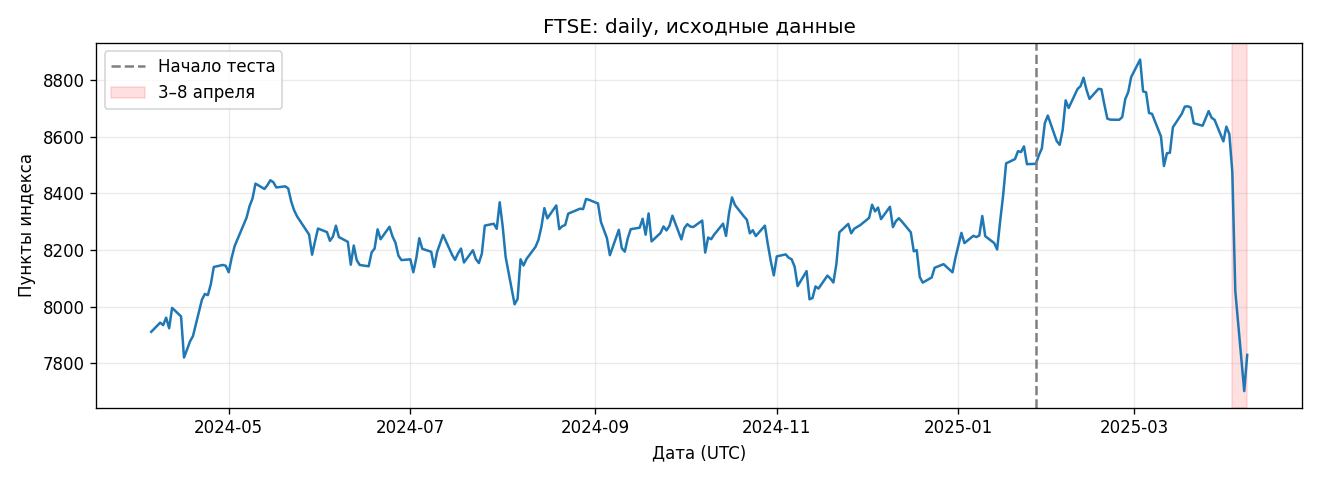

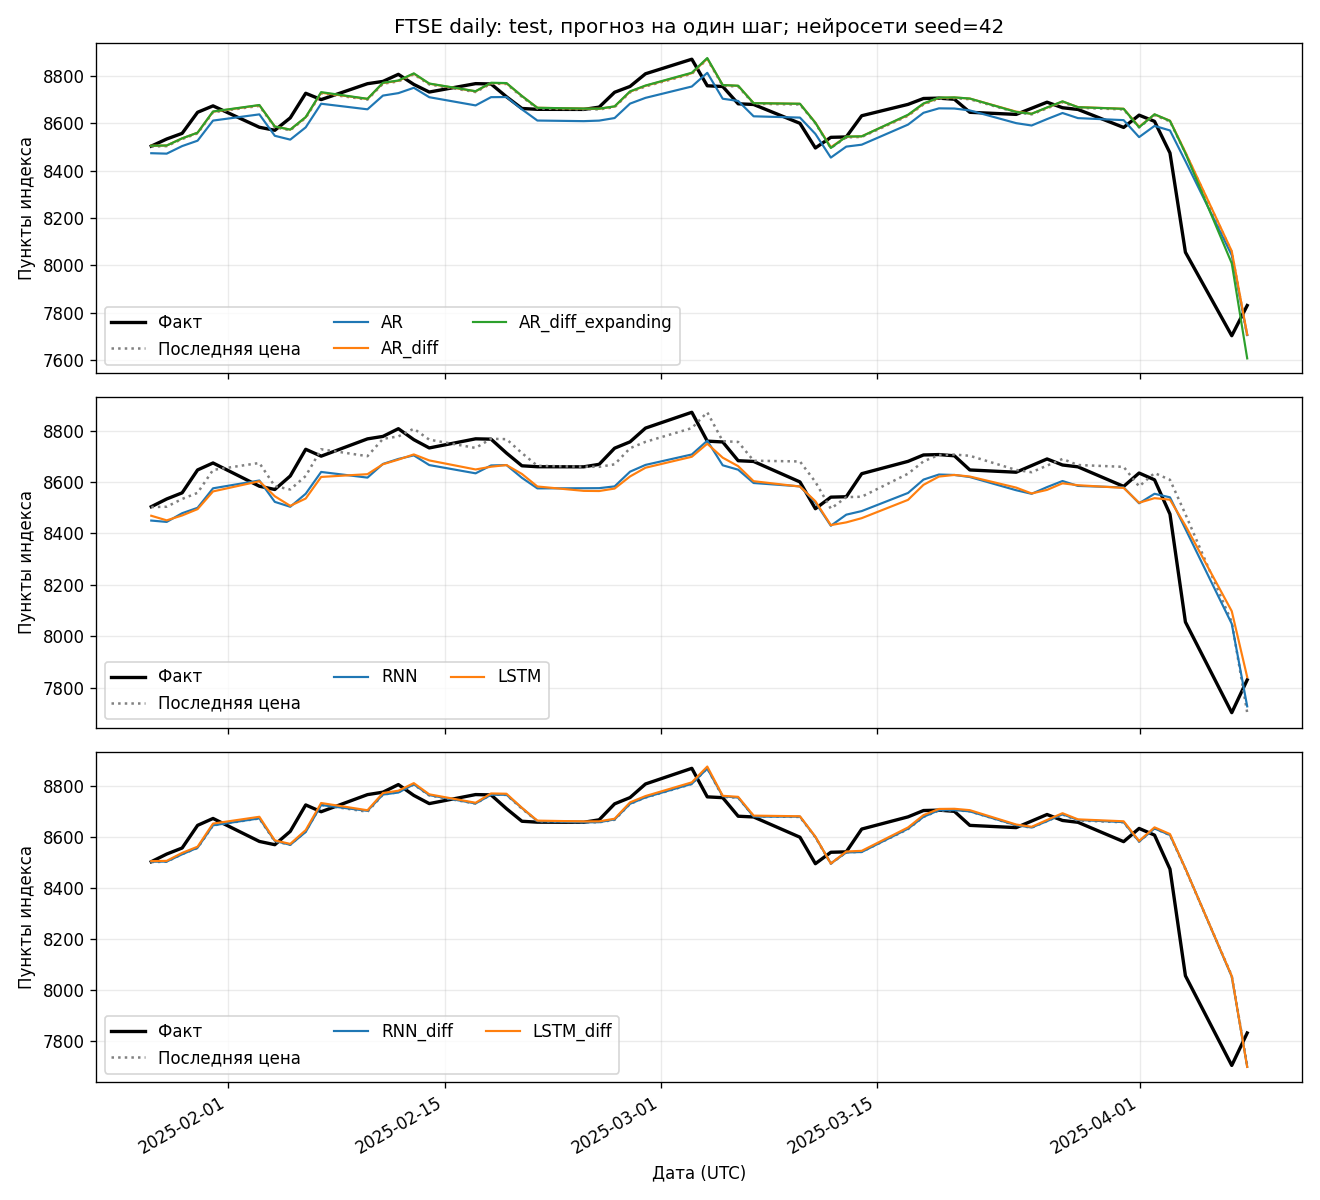

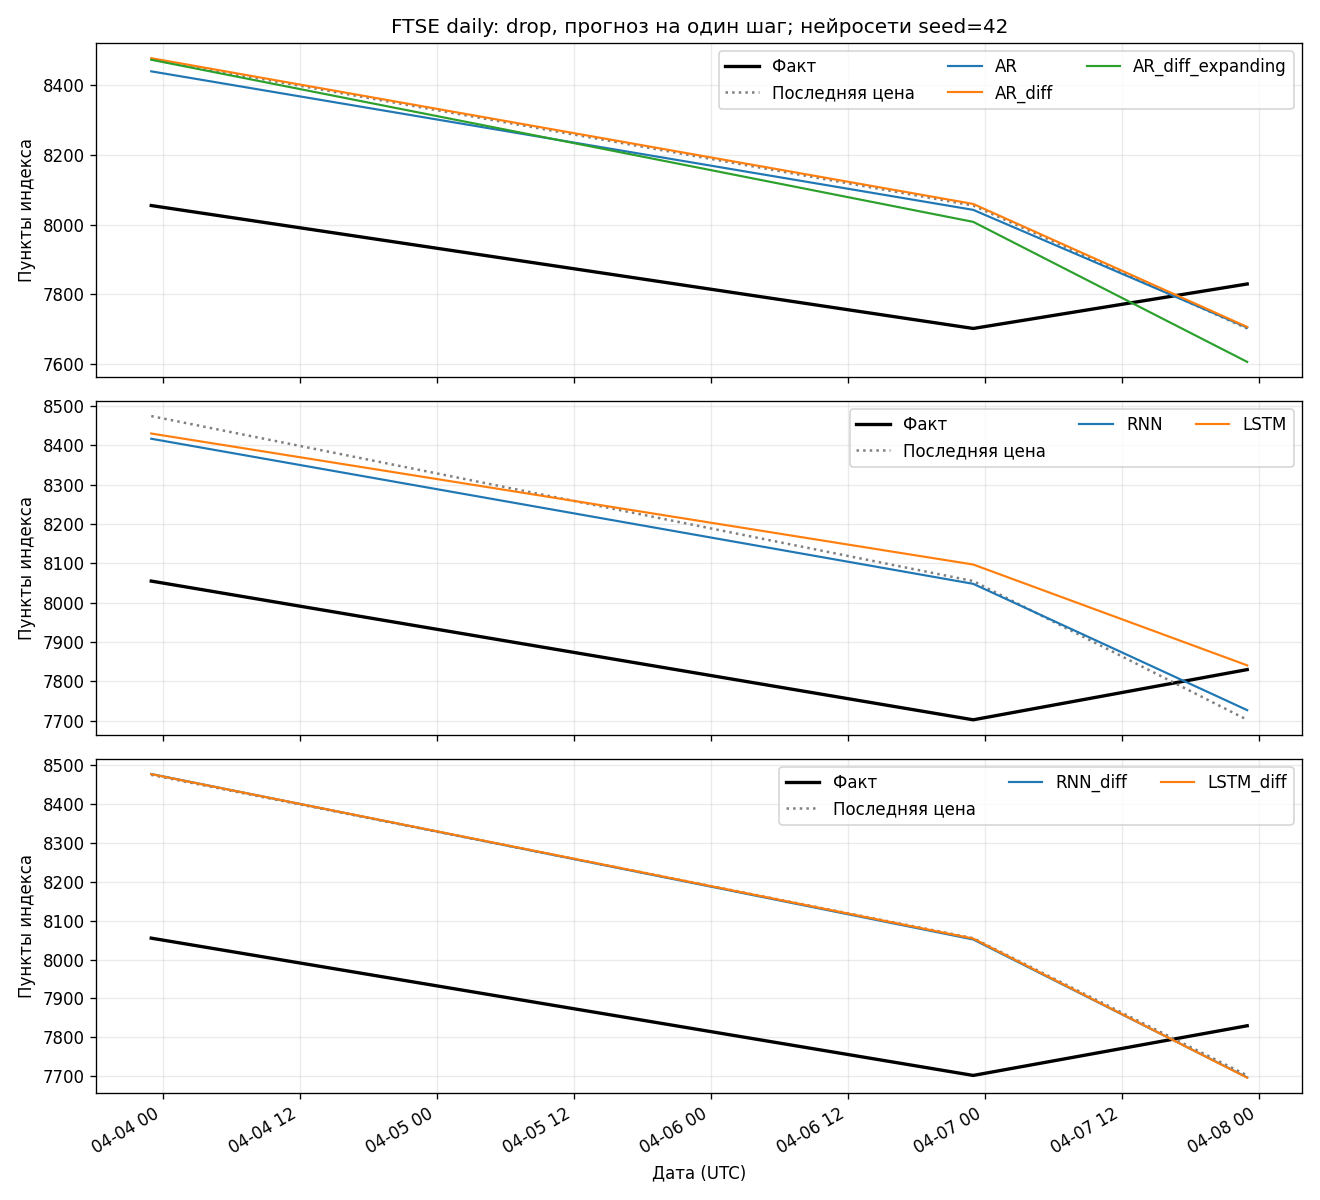

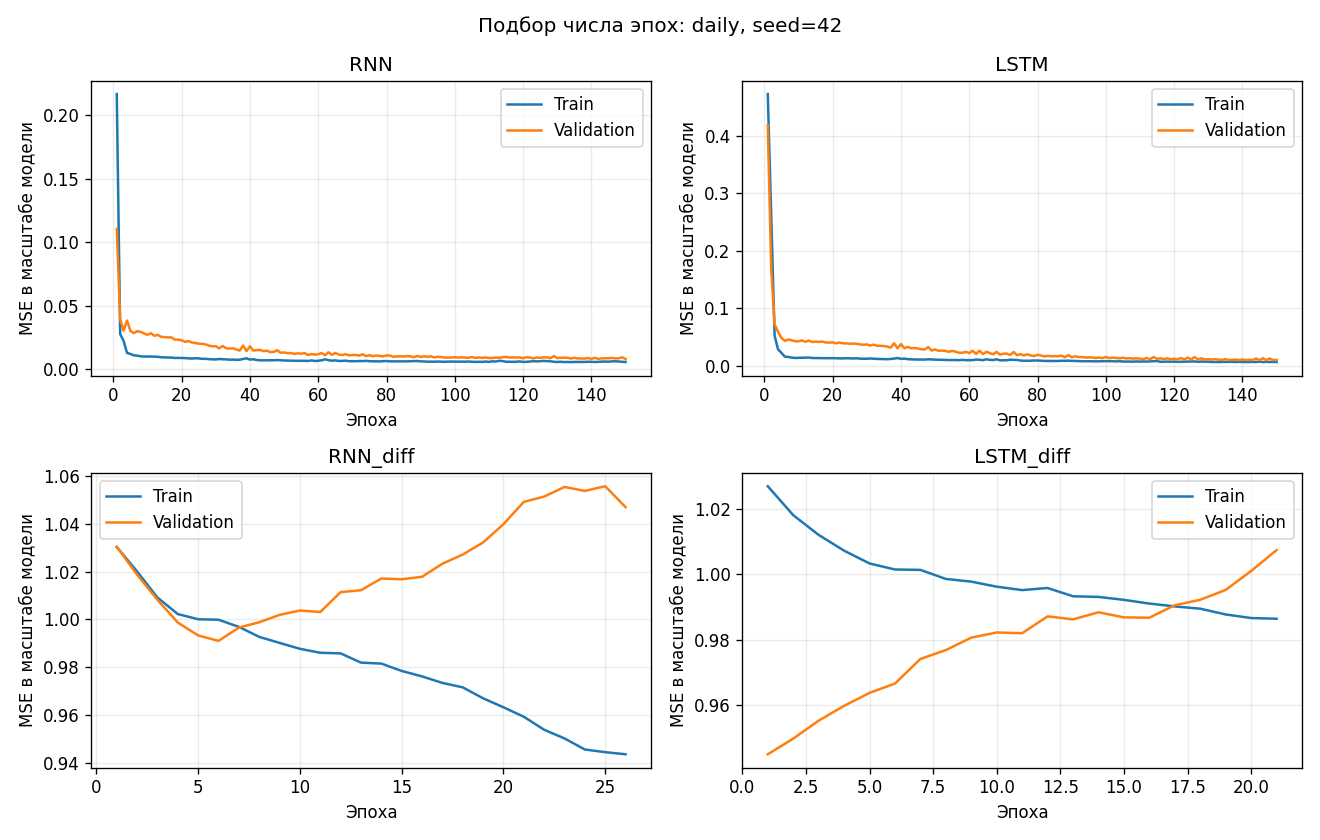

,dataset,period,model,n,MSE_mean,MAE_mean,RMSE_mean,RMSE_std,runs
6,4h,drop,RNN,10,26937.923,124.110,164.091,3.462,3
1,4h,drop,AR_diff,10,27405.008,131.667,165.545,0.000,1
0,4h,drop,AR,10,27492.782,131.248,165.809,0.000,1
4,4h,drop,LSTM_diff,10,28278.860,128.660,168.160,1.105,3
7,4h,drop,RNN_diff,10,28806.523,130.143,169.717,1.617,3
5,4h,drop,Naive,10,28864.667,129.296,169.896,0.000,1
2,4h,drop,AR_diff_expanding,10,32738.138,147.860,180.937,0.000,1
3,4h,drop,LSTM,10,48931.648,185.430,220.372,19.175,3


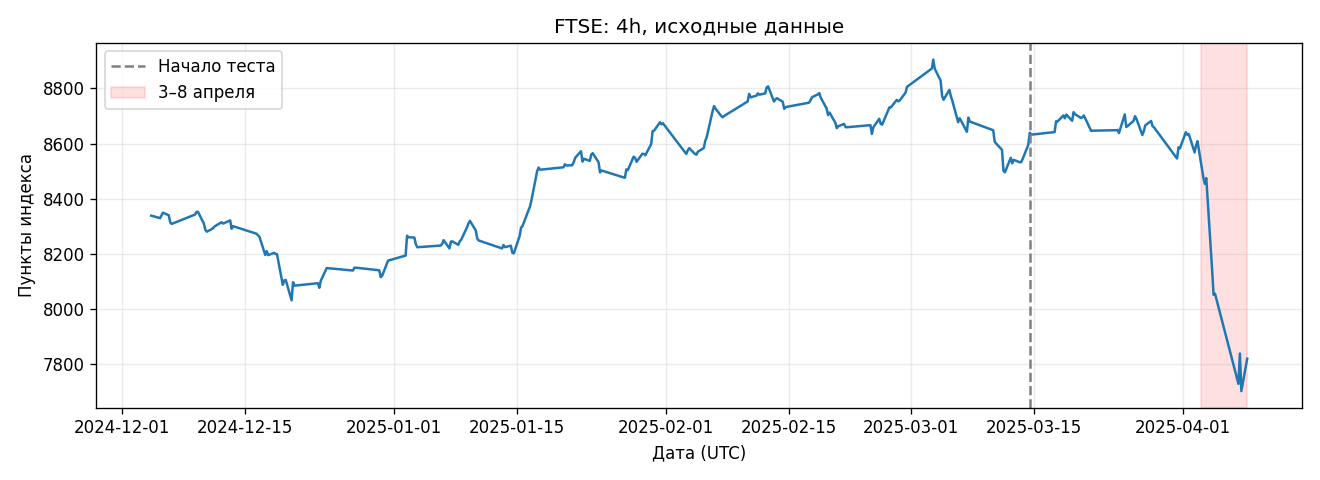

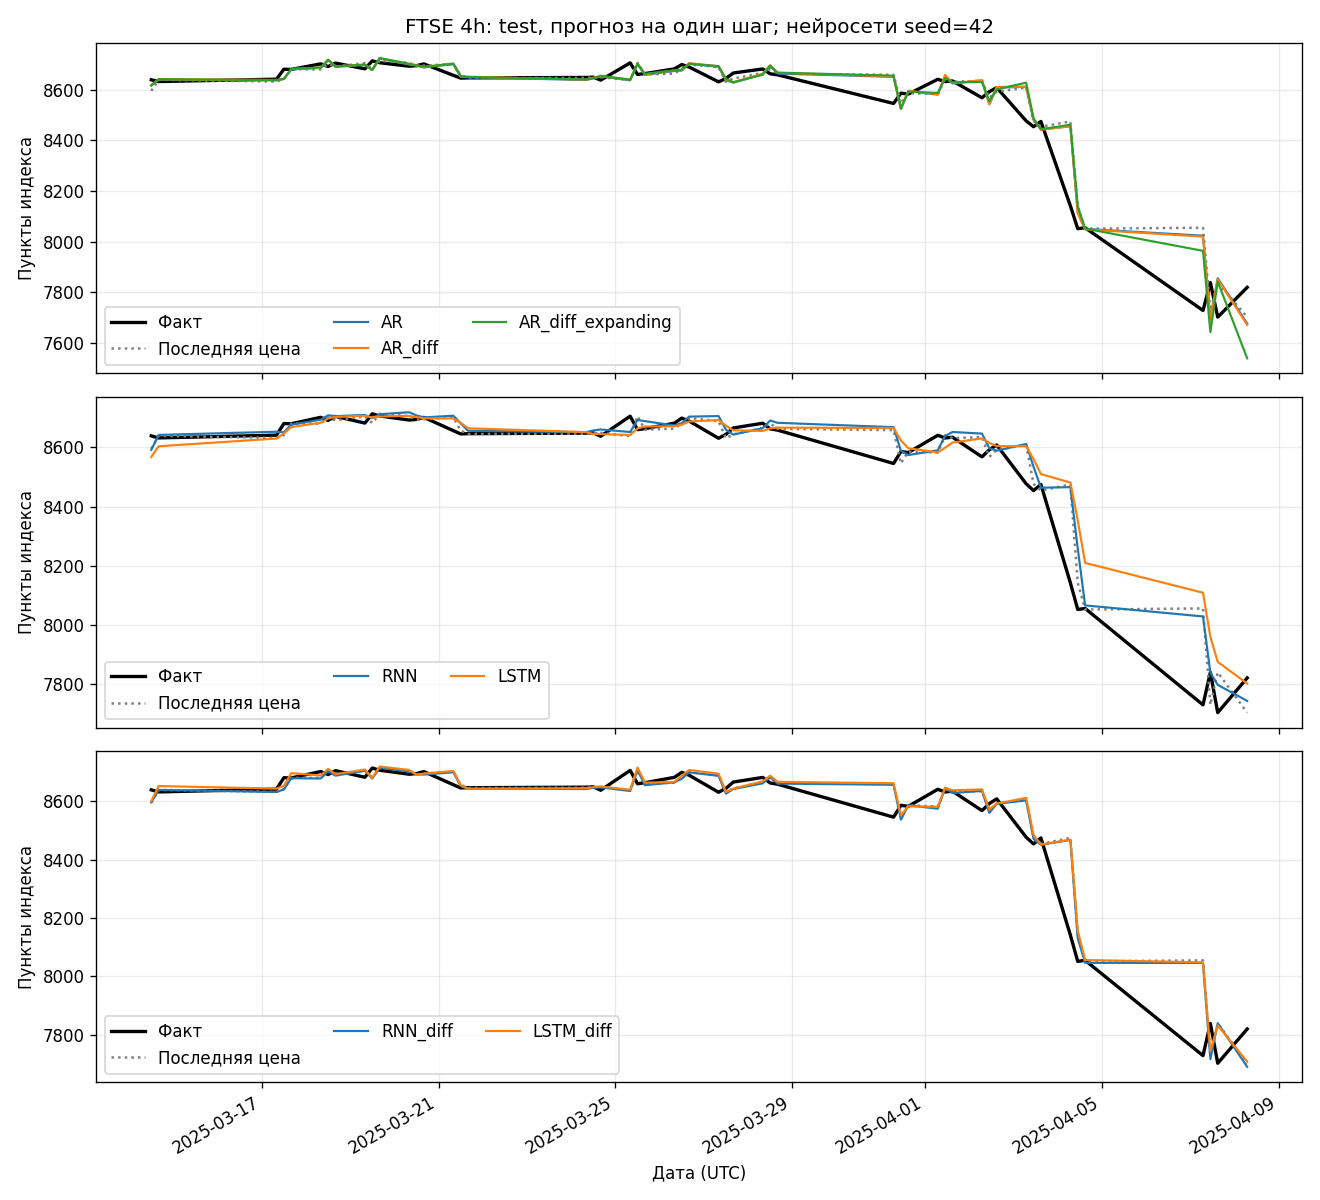

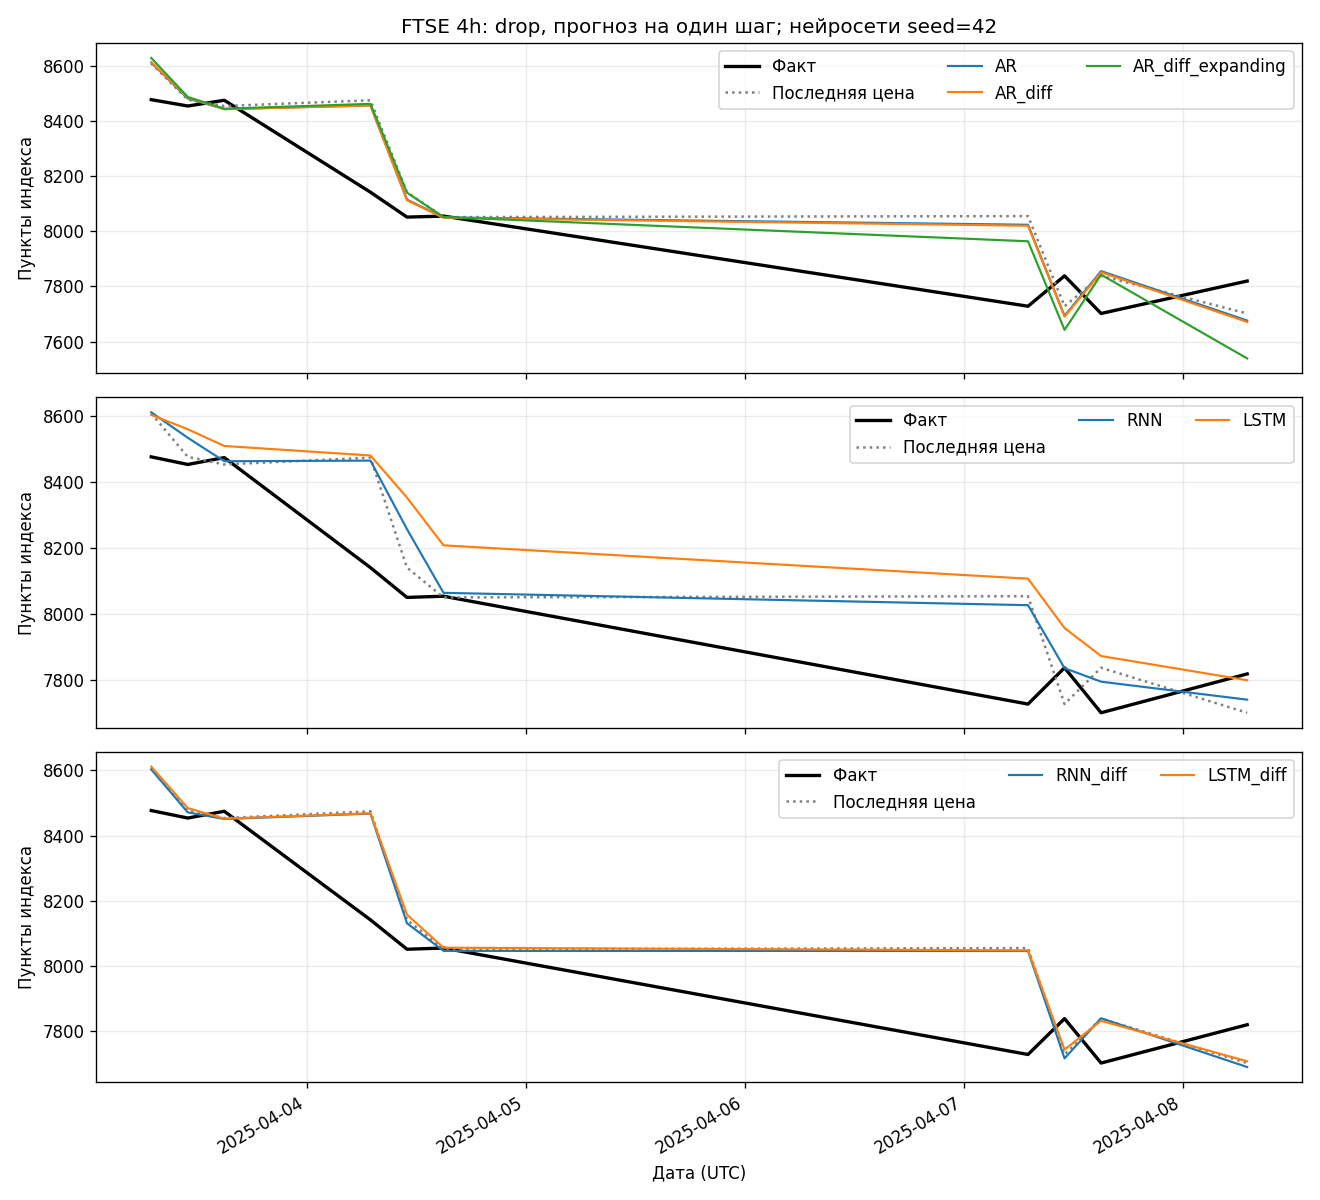

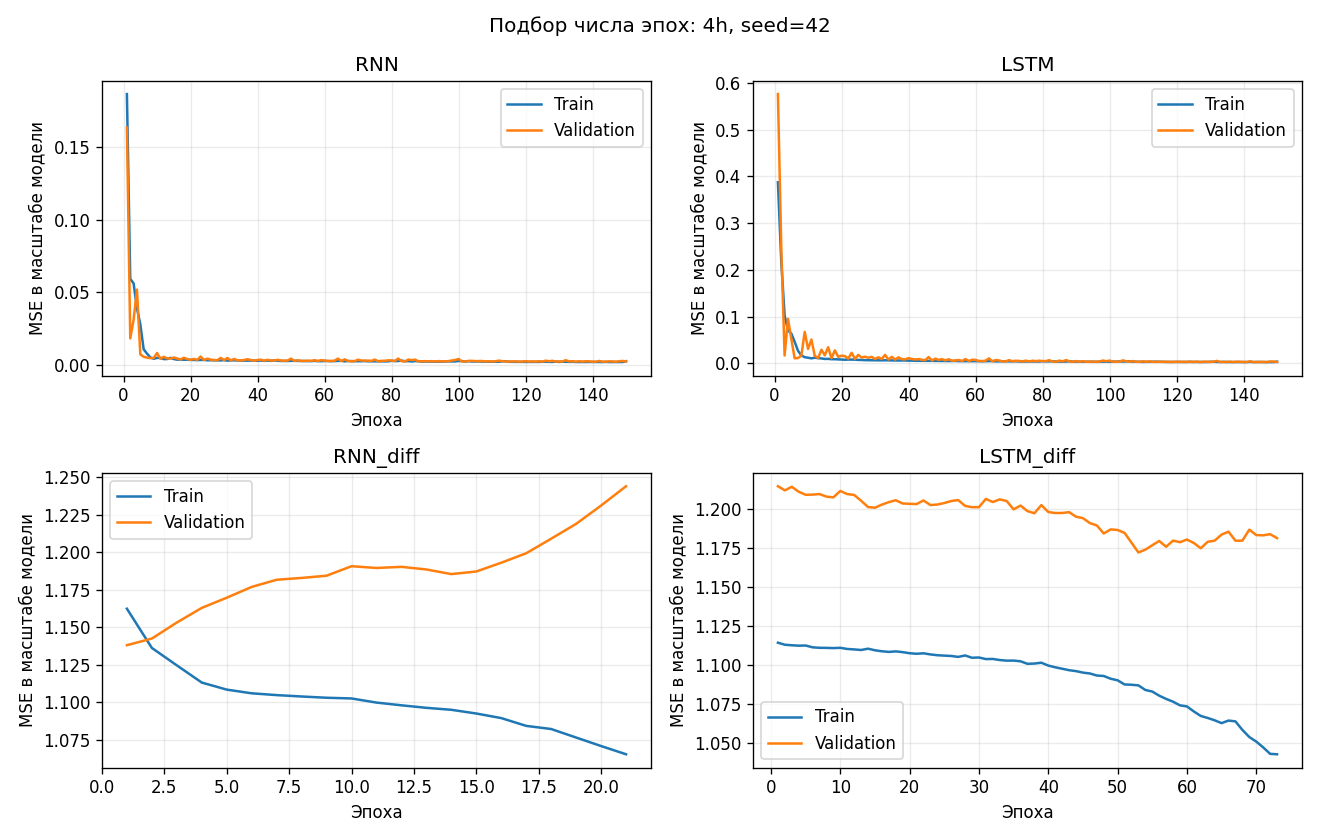

In [8]:
from IPython.display import Image, display
for dataset in DATASETS:
    print('Набор:', dataset)
    display(summary[(summary.dataset == dataset) & (summary.period == 'drop')]
            .sort_values('RMSE_mean').round(3))
    for suffix in ('series', 'test', 'drop', 'loss'):
        display(Image(filename=f'results/{dataset}_{suffix}.png'))


## 8. Почему RNN и LSTM могли оказаться хуже?

1. В исходном шаблоне scaler обучался на всём ряду, включая тест. Здесь утечка устранена.
2. AR сравнивался с нормализованными значениями, хотя прогноз был в пунктах индекса.
   Здесь все модели оцениваются в одном масштабе и на одних датах.
3. `range(len(data)-seq_length-1)` терял последний пример. Последующее обрезание прогнозов
   смещало их относительно целей. Здесь каждое окно связано с конкретным индексом цели.
4. В исходном AR история пополнялась, но не использовалась в прогнозе. Здесь лаги действительно обновляются.
5. Последний minibatch не представляет среднюю потерю эпохи. Здесь сохраняется среднее по всем примерам.
6. На небольшой выборке двухслойная LSTM может переобучаться. Использованы validation, ограничение градиента,
   слабая L2-регуляризация и более компактные модели разностей.
7. При смене ценового уровня сеть, обученная на уровнях, может плохо экстраполировать. Разности и восстановление
   от последней цены уменьшают эту проблему, но не дают информации о будущих новостях.

**Ограничение:** улучшение одношагового RMSE не означает, что модель заранее предсказала политическое событие
или всё падение. После первого падения следующие прогнозы уже получают новые низкие цены.
На апрельском отрезке мало наблюдений, поэтому выводы относятся только к этим данным.


In [9]:
# Выводы вычисляются из текущего запуска, а не из заранее заданных чисел.
for dataset in DATASETS:
    for period in ('test', 'drop'):
        rows = summary[(summary.dataset == dataset) & (summary.period == period)].set_index('model')
        winner = rows.RMSE_mean.idxmin()
        print(f'{dataset}, {period}: минимальный средний RMSE у {winner}: {rows.loc[winner, "RMSE_mean"]:.2f}')
        for kind in ('RNN', 'LSTM'):
            before, after = rows.loc[kind, 'RMSE_mean'], rows.loc[kind+'_diff', 'RMSE_mean']
            print(f'  {kind}: уровни {before:.2f}; разности {after:.2f}; изменение RMSE {(after/before-1)*100:+.1f}%')
        print(f'  Ориентир Naive: {rows.loc["Naive", "RMSE_mean"]:.2f}; наблюдений: {int(rows.loc[winner, "n"])}')


daily, test: минимальный средний RMSE у Naive: 93.69
  RNN: уровни 119.12; разности 93.79; изменение RMSE -21.3%
  LSTM: уровни 117.61; разности 94.39; изменение RMSE -19.7%
  Ориентир Naive: 93.69; наблюдений: 52
daily, drop: минимальный средний RMSE у RNN: 293.83
  RNN: уровни 293.83; разности 324.87; изменение RMSE +10.6%
  LSTM: уровни 321.25; разности 328.31; изменение RMSE +2.2%
  Ориентир Naive: 325.06; наблюдений: 3
4h, test: минимальный средний RMSE у RNN: 78.69
  RNN: уровни 78.69; разности 81.12; изменение RMSE +3.1%
  LSTM: уровни 105.24; разности 80.17; изменение RMSE -23.8%
  Ориентир Naive: 80.74; наблюдений: 51
4h, drop: минимальный средний RMSE у RNN: 164.09
  RNN: уровни 164.09; разности 169.72; изменение RMSE +3.4%
  LSTM: уровни 220.37; разности 168.16; изменение RMSE -23.7%
  Ориентир Naive: 169.90; наблюдений: 10
